In [1]:
#Análisis de los sismos y el ruido, si son estacionarios, se usan trazas del canal Z.
import sys
import warnings
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
from src.data_loader import leer_metadata, cargar, armar_split
from src.dsp_filters import FS, BANDA, SOS, filtrar

#Se ocultan los avisos de KPSS cuando el p-valor queda fuera de su tabla, es decir no cambia el resultado.
warnings.filterwarnings('ignore', category=InterpolationWarning)
df = leer_metadata()
df['split'] = armar_split(df)['split'].values
train = df[df['split'] == 'train']
ruido = train[train['trace_category'] == 'noise']
sismos = train[train['trace_category'] == 'earthquake_local']

#Descarto las trazas de ruido con desvío en canal z menor a esto:
MUERTA = 0.1 #Se utiliza en las siguientes celdas

def canal_z(fila):
    return cargar(fila.trace_name, fila.chunk)[:, 2].astype(float)

len(ruido), len(sismos)

(164797, 300930)

## Estacionariedad

La requiere Welch, que promedia espectros de pedazos de la señal, y el STA/LTA, que usa el promedio largo como nivel de referencia del ruido.

Primero una traza de cada tipo, con media y desvío móviles en ventanas de 5 s.

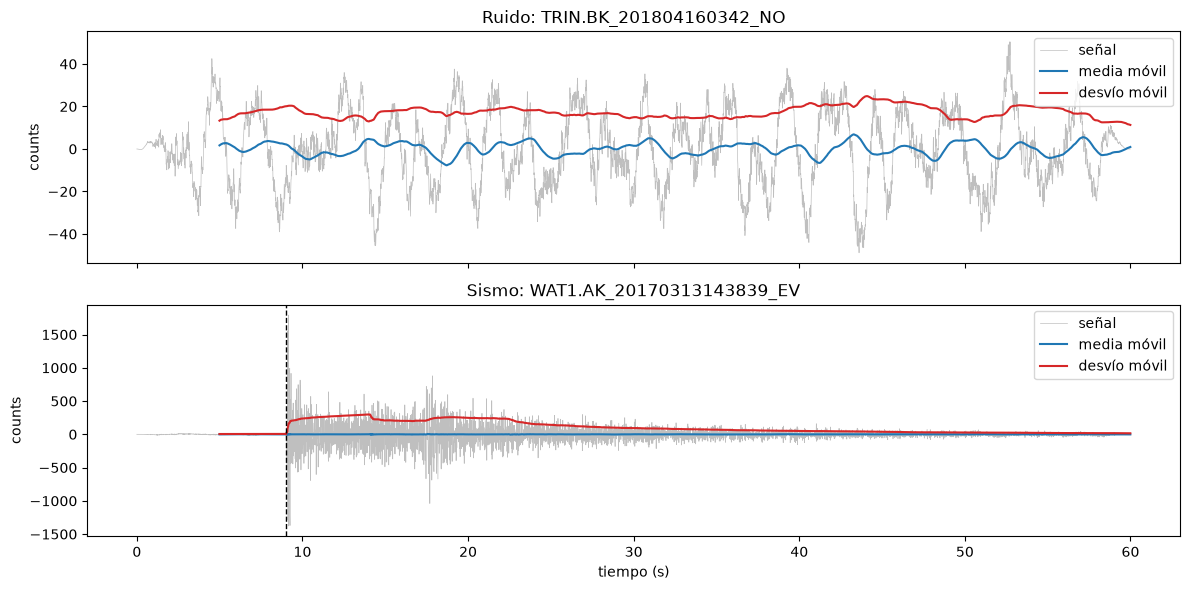

In [2]:
#Se toman ventanas de 5 s (500 muestras)
VENTANA = 5 * FS

#Se toma la primera traza de ruido que tenga el canal Z vivo
ej_ruido = next(fila for _, fila in ruido.sample(20, random_state=1).iterrows() if canal_z(fila).std() >= MUERTA)
ej_sismo = sismos.sample(1, random_state=1).iloc[0]
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, fila, titulo in [(axs[0], ej_ruido, 'Ruido'), (axs[1], ej_sismo, 'Sismo')]:
    z = pd.Series(canal_z(fila))
    t = np.arange(len(z)) / FS
    ax.plot(t, z, color='0.75', lw=0.5, label='señal')
    ax.plot(t, z.rolling(VENTANA).mean(), color='C0', label='media móvil')
    ax.plot(t, z.rolling(VENTANA).std(), color='C3', label='desvío móvil')
    ax.set_title(f"{titulo}: {fila['trace_name']}")
    ax.set_ylabel('counts')
    ax.legend(loc='upper right')
#Se marca la llegada de la P
axs[1].axvline(ej_sismo['p_arrival_sample'] / FS, color='k', ls='--', lw=1)
axs[1].set_xlabel('tiempo (s)')
plt.tight_layout()

La media queda aproximadamente en cero en las dos, pero el desvío varía. En el caso del ruido, es aproximadamente estacionario, mientras que en el sismo salta cuando llega la P.

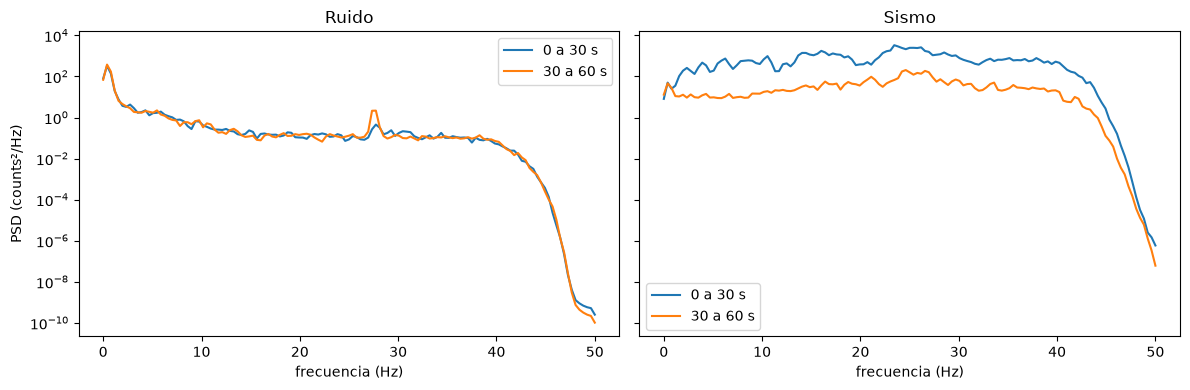

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, fila, titulo in [(axs[0], ej_ruido, 'Ruido'), (axs[1], ej_sismo, 'Sismo')]:
    z = canal_z(fila)
    f, p1 = signal.welch(z[:3000], fs=FS, nperseg=256)
    f, p2 = signal.welch(z[3000:], fs=FS, nperseg=256)
    ax.semilogy(f, p1, label='0 a 30 s')
    ax.semilogy(f, p2, label='30 a 60 s')
    ax.set_title(titulo)
    ax.set_xlabel('frecuencia (Hz)')
    ax.legend()
axs[0].set_ylabel('PSD (counts²/Hz)')
plt.tight_layout()

En frecuencia ocurre lo mismo, se utiliza PSD.

### Utilización de tests sobre 300 trazas de cada tipo

- **ADF** (Dickey-Fuller aumentado): la hipótesis nula es que la serie no es estacionaria. Si p < 0.05, se toma como estacionaria.
- **KPSS**: la hipótesis nula es que sí es estacionaria. Si p < 0.05, se toma como no estacionaria.
- **Cociente de desvíos**: se corta la traza en 12 ventanas de 5 s y se divide el desvío más grande por el más chico. Si la varianza no cambia da cerca de 1.

In [4]:
N_TEST = 300
filas = []
muertas = {'ruido': 0, 'sismo': 0}
for tipo, tabla in [('ruido', ruido), ('sismo', sismos)]:
    for fila in tabla.sample(N_TEST, random_state=0).itertuples():
        z = canal_z(fila)
        if z.std() < MUERTA:
            muertas[tipo] += 1
            continue
        z = z - z.mean()
        #Se calcula un desvío por cada ventana de 5 s
        desvios = z.reshape(12, VENTANA).std(axis=1)
        filas.append({
            'tipo': tipo,
            'adf_p': adfuller(z, autolag='AIC', result_object=False)[1],
            'kpss_p': kpss(z, regression='c', nlags='auto', result_object=False)[1],
            'cociente_desvios': desvios.max() / desvios.min(),
        })
tests = pd.DataFrame(filas)
print('Trazas muertas descartadas:', muertas)

#Se calcula el porcentaje de trazas que cumple cada condición
resumen = tests.groupby('tipo').agg(
    adf_estacionaria=('adf_p', lambda p: (p < 0.05).mean() * 100),
    kpss_no_estacionaria=('kpss_p', lambda p: (p < 0.05).mean() * 100),
    cociente_mediano=('cociente_desvios', 'median'),
    cociente_mayor_a_3=('cociente_desvios', lambda c: (c > 3).mean() * 100),
)
resumen.round(1)

Trazas muertas descartadas: {'ruido': 1, 'sismo': 0}


,adf_estacionaria,kpss_no_estacionaria,cociente_mediano,cociente_mayor_a_3
tipo,,,,
ruido,100.0,0.0,1.6,9.0
sismo,100.0,0.0,14.4,93.7


Según ADF y KPSS las dos son estacionarias. Esto se debe a que estos tests miran si la media se va corriendo con el tiempo, y en STEAD la media siempre está aproximadamente en cero. En el sismo lo que cambia es la varianza.

Sí se puede ver en el cociente de desvíos, en el caso del ruido la varianza es casi constante, mientras que en el sismo no.

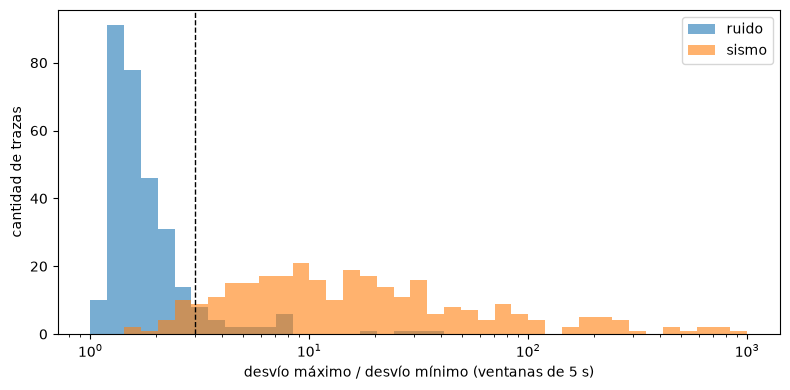

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, 3, 40)
for tipo in ['ruido', 'sismo']:
    ax.hist(tests.loc[tests['tipo'] == tipo, 'cociente_desvios'], bins=bins, alpha=0.6, label=tipo)
ax.axvline(3, color='k', ls='--', lw=1)
ax.set_xscale('log')
ax.set_xlabel('desvío máximo / desvío mínimo (ventanas de 5 s)')
ax.set_ylabel('cantidad de trazas')
ax.legend()
plt.tight_layout()

## Espectro del ruido

PSD mediana de 300 trazas de ruido.

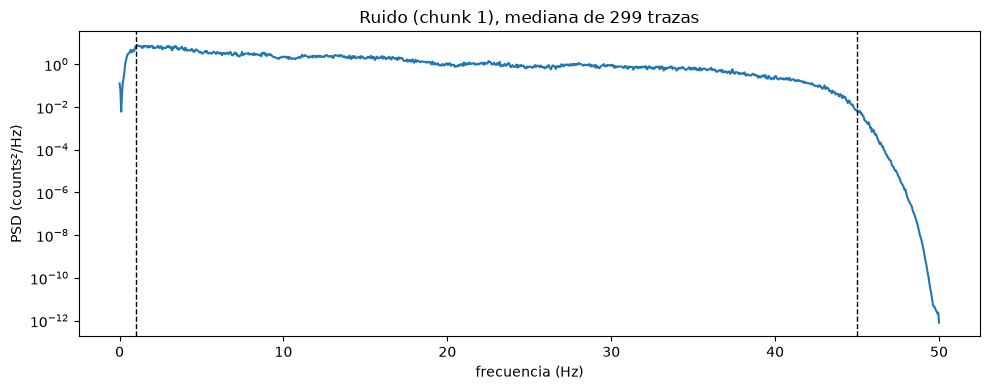

In [6]:
psd_ruido = []
for fila in ruido.sample(300, random_state=0).itertuples():
    z = canal_z(fila)
    if z.std() < MUERTA:
        continue
    f_r, p = signal.welch(z, fs=FS, nperseg=2048)
    psd_ruido.append(p)

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(f_r, np.median(psd_ruido, axis=0))
ax.axvline(1, color='k', ls='--', lw=1)
ax.axvline(45, color='k', ls='--', lw=1)
ax.set_xlabel('frecuencia (Hz)')
ax.set_ylabel('PSD (counts²/Hz)')
ax.set_title(f'Ruido (chunk 1), mediana de {len(psd_ruido)} trazas')
plt.tight_layout()

La potencia cae repentinamente arriba de 44 Hz y abajo de 0.5 Hz. Esto se debe a que los datos de STEAD ya vienen filtrados entre 1 y 45 Hz.

## Sismo contra ruido

En cada sismo se compara el ruido hasta 1 s antes de la P con los 10 s que le siguen. Se toma la mediana de 500 sismos, se dejan afuera los que tienen la P antes de los 4 s, porque casi no tienen ruido previo.

In [ ]:
psd_r, psd_s = [], []
for fila in sismos.sample(500, random_state=0).itertuples():
    p = int(fila.p_arrival_sample)
    if p < 4 * FS:
        continue
    z = canal_z(fila)
    f, a = signal.welch(z[:p - FS], fs=FS, nperseg=256)
    f, b = signal.welch(z[p:p + 10 * FS], fs=FS, nperseg=256)
    psd_r.append(a)
    psd_s.append(b)
n_usados = len(psd_s)
psd_r, psd_s = np.median(psd_r, axis=0), np.median(psd_s, axis=0)
ratio_db = 10 * np.log10(psd_s / psd_r)

#Se buscan las frecuencias donde el sismo supera al ruido para cada umbral
for umbral in [10, 20]:
    arriba = f[ratio_db >= umbral]
    print(f'>= {umbral} dB: de {arriba.min():.1f} a {arriba.max():.1f} Hz')

>= 10 dB: de 1.2 a 45.3 Hz
>= 20 dB: de 3.1 a 21.9 Hz


Con 20 dB queda entre 3 y 22 Hz, que es donde el sismo le gana claramente al ruido. Se elige 3–20 Hz, que es `BANDA` en `src/dsp_filters.py`.

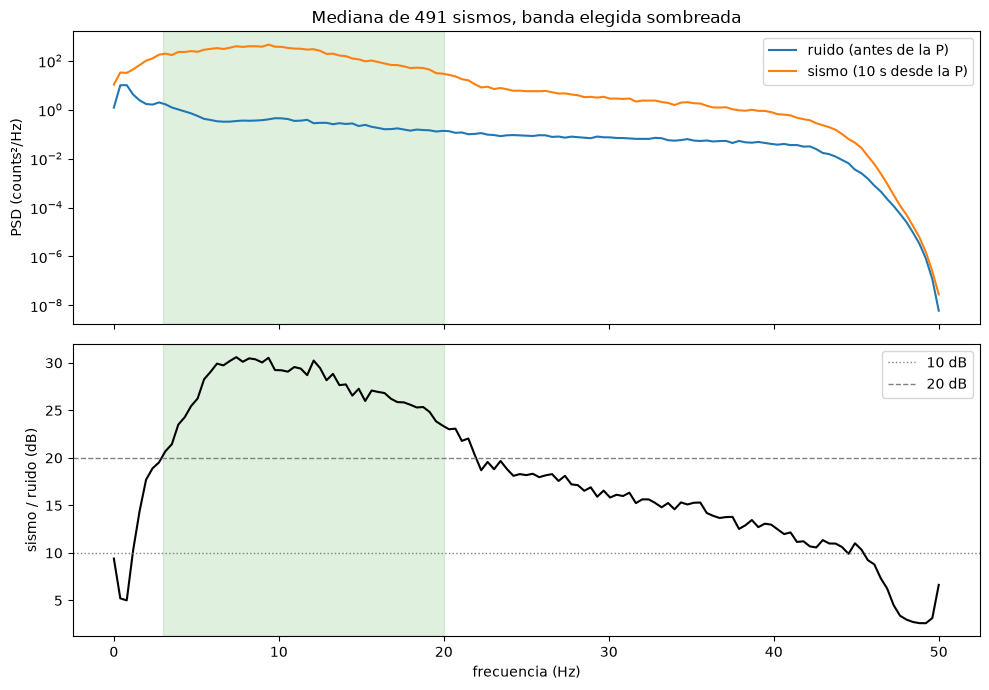

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axs[0].semilogy(f, psd_r, label='ruido (antes de la P)')
axs[0].semilogy(f, psd_s, label='sismo (10 s desde la P)')
axs[0].set_ylabel('PSD (counts²/Hz)')
axs[0].set_title(f'Mediana de {n_usados} sismos, banda elegida sombreada')
axs[0].legend()
axs[1].plot(f, ratio_db, color='k')
axs[1].axhline(10, color='0.5', ls=':', lw=1, label='10 dB')
axs[1].axhline(20, color='0.5', ls='--', lw=1, label='20 dB')
axs[1].set_ylabel('sismo / ruido (dB)')
axs[1].set_xlabel('frecuencia (Hz)')
axs[1].legend()
for ax in axs:
    ax.axvspan(*BANDA, color='C2', alpha=0.15)
plt.tight_layout()

### Otros canales

La banda se eligió con el canal Z, donde mejor se ve la P. Como la S se mueve mayormente en horizontal, se revisan también E y N con los mismos sismos y las mismas ventanas.

E: >= 20 dB de 2.7 a 22.7 Hz
N: >= 20 dB de 2.7 a 22.7 Hz
Z: >= 20 dB de 3.1 a 21.9 Hz


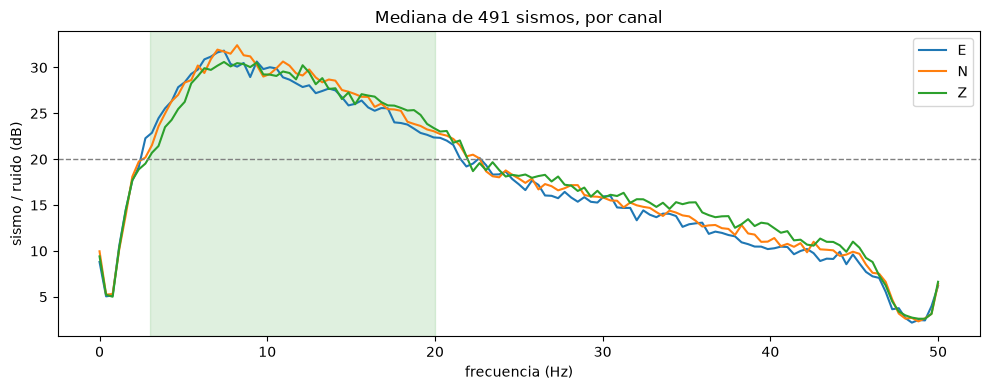

In [ ]:
CANALES = ['E', 'N', 'Z']
psd_r3, psd_s3 = [], []
for fila in sismos.sample(500, random_state=0).itertuples():
    p = int(fila.p_arrival_sample)
    if p < 4 * FS:
        continue
    x = cargar(fila.trace_name, fila.chunk).astype(float)
    #Se calcula la PSD de los 3 canales a la vez
    f, a = signal.welch(x[:p - FS], fs=FS, nperseg=256, axis=0)
    f, b = signal.welch(x[p:p + 10 * FS], fs=FS, nperseg=256, axis=0)
    psd_r3.append(a)
    psd_s3.append(b)
ratio_db3 = 10 * np.log10(np.median(psd_s3, axis=0) / np.median(psd_r3, axis=0))

#Se buscan las frecuencias donde el sismo supera al ruido por 20 dB en cada canal
for i, canal in enumerate(CANALES):
    arriba = f[ratio_db3[:, i] >= 20]
    print(f'{canal}: >= 20 dB de {arriba.min():.1f} a {arriba.max():.1f} Hz')

fig, ax = plt.subplots(figsize=(10, 4))
for i, canal in enumerate(CANALES):
    ax.plot(f, ratio_db3[:, i], label=canal)
ax.axhline(20, color='0.5', ls='--', lw=1)
ax.axvspan(*BANDA, color='C2', alpha=0.15)
ax.set_xlabel('frecuencia (Hz)')
ax.set_ylabel('sismo / ruido (dB)')
ax.set_title(f'Mediana de {len(psd_s3)} sismos, por canal')
ax.legend()
plt.tight_layout()

La banda de 3–20 Hz sirve para los tres.

## Filtro

El diseño y la prueba del filtro están en `filters_design_freq.ipynb`.